In [1]:
import numpy as np

# ---- Initialise the network ----
np.random.seed(1)
W1 = np.random.randn(3, 4)    # 3 inputs  -> 4 hidden neurons
b1 = np.zeros(4)              # one bias per hidden neuron
W2 = np.random.randn(4, 1)    # 4 hidden  -> 1 output neuron
b2 = np.zeros(1)              # one bias for the output neuron

print("Shapes:")
print("  W1:", W1.shape, "  b1:", b1.shape)
print("  W2:", W2.shape, "  b2:", b2.shape)

# ---- Activation functions ----
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# ---- Forward pass ----
def forward(x):
    z1 = x @ W1 + b1      # weighted sums of the hidden layer (4 numbers)
    h = relu(z1)          # hidden values after ReLU
    z2 = h @ W2 + b2      # weighted sum of the output neuron (1 number)
    y = sigmoid(z2)       # output probability
    return z1, h, z2, y

x = np.array([0.5, -1.2, 3.0])
z1, h, z2, y = forward(x)

print("\nInput x:", x)
print("Hidden before ReLU (z1):", z1.round(3))
print("Hidden after ReLU  (h): ", h.round(3))
print("Output before sigmoid (z2):", z2.round(3))
print("Output probability (y):    ", y.round(3))

Shapes:
  W1: (3, 4)   b1: (4,)
  W2: (4, 1)   b2: (1,)

Input x: [ 0.5 -1.2  3. ]
Hidden before ReLU (z1): [ 0.731  1.708  2.028 -5.803]
Hidden after ReLU  (h):  [0.731 1.708 2.028 0.   ]
Output before sigmoid (z2): [1.408]
Output probability (y):     [0.803]


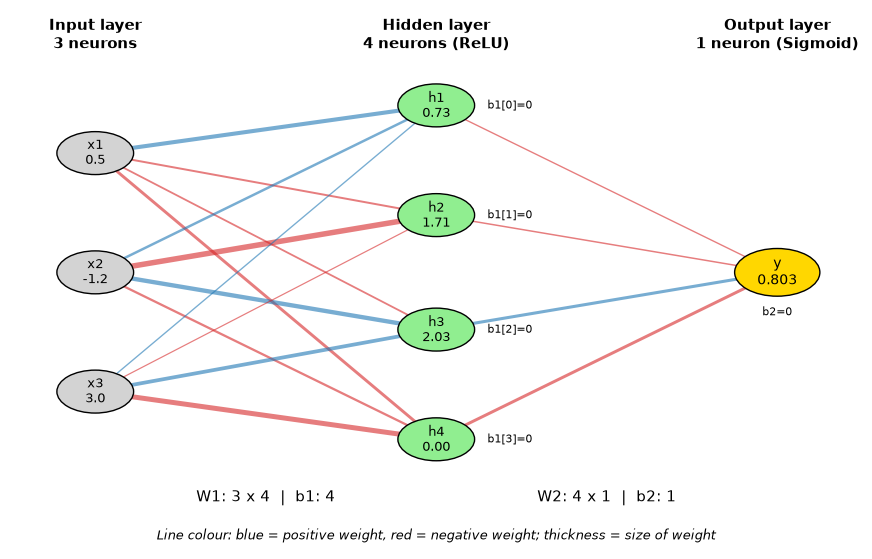

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 7))
ax.axis("off")
xin, xhid, xout = 0.1, 0.5, 0.9
yin = [0.75, 0.5, 0.25]
yhid = [0.85, 0.62, 0.38, 0.15]
yout = 0.5

# Connections: blue = positive weight, red = negative, thicker = bigger weight
for i, yi in enumerate(yin):
    for j, yj in enumerate(yhid):
        w = W1[i, j]
        ax.plot([xin, xhid], [yi, yj], color="tab:blue" if w > 0 else "tab:red",
                lw=0.5 + 1.5 * abs(w), alpha=0.6, zorder=1)
for j, yj in enumerate(yhid):
    w = W2[j, 0]
    ax.plot([xhid, xout], [yj, yout], color="tab:blue" if w > 0 else "tab:red",
            lw=0.5 + 1.5 * abs(w), alpha=0.6, zorder=1)

# Neurons with their values
for i, yi in enumerate(yin):
    ax.add_patch(plt.Circle((xin, yi), 0.045, color="lightgray", ec="black", zorder=2))
    ax.text(xin, yi, f"x{i+1}\n{x[i]}", ha="center", va="center", fontsize=9, zorder=3)
for j, yj in enumerate(yhid):
    ax.add_patch(plt.Circle((xhid, yj), 0.045, color="lightgreen", ec="black", zorder=2))
    ax.text(xhid, yj, f"h{j+1}\n{h[j]:.2f}", ha="center", va="center", fontsize=9, zorder=3)
    ax.text(xhid + 0.06, yj, f"b1[{j}]={b1[j]:.0f}", fontsize=8, va="center")
ax.add_patch(plt.Circle((xout, yout), 0.05, color="gold", ec="black", zorder=2))
ax.text(xout, yout, f"y\n{y[0]:.3f}", ha="center", va="center", fontsize=10, zorder=3)
ax.text(xout, yout - 0.09, f"b2={b2[0]:.0f}", ha="center", fontsize=8)

# Labels
ax.text(xin, 0.97, "Input layer\n3 neurons", ha="center", fontsize=11, weight="bold")
ax.text(xhid, 0.97, "Hidden layer\n4 neurons (ReLU)", ha="center", fontsize=11, weight="bold")
ax.text(xout, 0.97, "Output layer\n1 neuron (Sigmoid)", ha="center", fontsize=11, weight="bold")
ax.text((xin + xhid) / 2, 0.02, "W1: 3 x 4  |  b1: 4", ha="center", fontsize=11)
ax.text((xhid + xout) / 2, 0.02, "W2: 4 x 1  |  b2: 1", ha="center", fontsize=11)
ax.text(0.5, -0.06, "Line colour: blue = positive weight, red = negative weight; thickness = size of weight",
        ha="center", fontsize=9, style="italic")
ax.set_xlim(0, 1)
ax.set_ylim(-0.08, 1.05)
plt.savefig("network_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 2 - Activation and loss functions

softmax([2.0, 1.0, 0.1]) = [0.659 0.242 0.099] (sum 1.0)


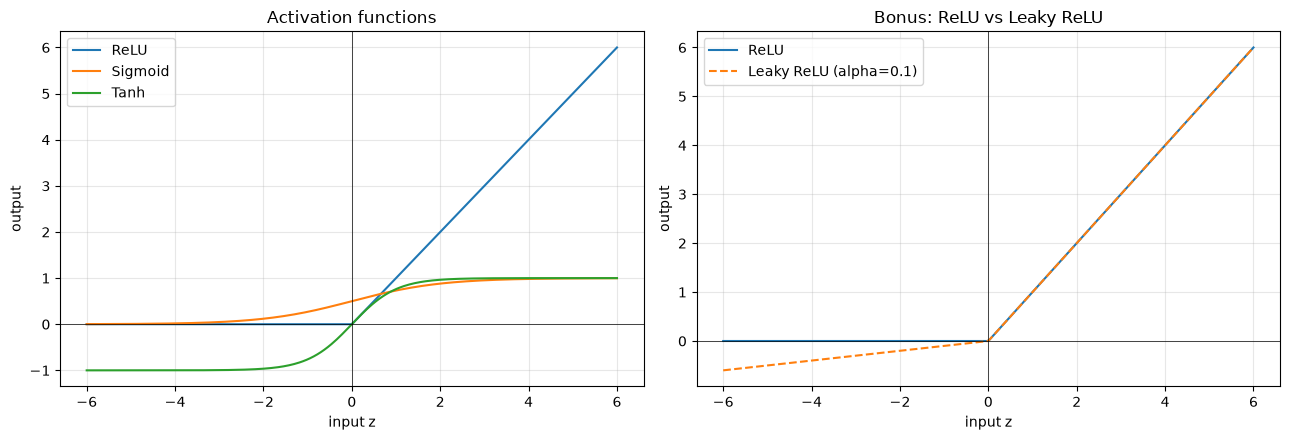


MSE on 3 predictions: true [3.0, 5.0, 2.5], pred [2.5, 5.5, 2.0] -> 0.25
Cross-entropy on 3 predictions: true [1, 0, 1], prob [0.9, 0.2, 0.7] -> 0.228

True label = 1:
  predicted 0.99  (confident and RIGHT      ) -> cross-entropy 0.010
  predicted 0.6   (uncertain, leaning right ) -> cross-entropy 0.511
  predicted 0.4   (uncertain, leaning wrong ) -> cross-entropy 0.916
  predicted 0.01  (confident and WRONG      ) -> cross-entropy 4.605


In [3]:
# ---- Softmax ----
def softmax(logits):
    e = np.exp(logits - np.max(logits))     # subtract max for numerical stability
    return e / e.sum()

s = softmax(np.array([2.0, 1.0, 0.1]))
print(f"softmax([2.0, 1.0, 0.1]) = {s.round(3)} (sum {s.sum():.1f})")

# ---- Plot ReLU, Sigmoid, Tanh (+ bonus Leaky ReLU) ----
def leaky_relu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)

z = np.linspace(-6, 6, 300)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(z, relu(z), label="ReLU")
axes[0].plot(z, sigmoid(z), label="Sigmoid")
axes[0].plot(z, np.tanh(z), label="Tanh")
axes[0].set_title("Activation functions")
axes[1].plot(z, relu(z), label="ReLU")
axes[1].plot(z, leaky_relu(z), "--", label="Leaky ReLU (alpha=0.1)")
axes[1].set_title("Bonus: ReLU vs Leaky ReLU")
for ax in axes:
    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_xlabel("input z")
    ax.set_ylabel("output")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("activations.png", dpi=150)
plt.show()

# ---- Loss functions ----
def mse(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean((y_true - y_pred) ** 2)

def cross_entropy(y_true, y_prob, eps=1e-12):
    y_true = np.array(y_true)
    y_prob = np.clip(np.array(y_prob), eps, 1 - eps)   # avoid log(0)
    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))

print("\nMSE on 3 predictions: true [3.0, 5.0, 2.5], pred [2.5, 5.5, 2.0] ->",
      round(mse([3.0, 5.0, 2.5], [2.5, 5.5, 2.0]), 3))
print("Cross-entropy on 3 predictions: true [1, 0, 1], prob [0.9, 0.2, 0.7] ->",
      round(cross_entropy([1, 0, 1], [0.9, 0.2, 0.7]), 3))

# ---- Confident wrong vs uncertain (true answer = 1) ----
print("\nTrue label = 1:")
for p, label in [(0.99, "confident and RIGHT"), (0.6, "uncertain, leaning right"),
                 (0.4, "uncertain, leaning wrong"), (0.01, "confident and WRONG")]:
    print(f"  predicted {p:<5} ({label:<25}) -> cross-entropy {cross_entropy([1], [p]):.3f}")

### Results
- Network shapes: W1: 3x4, b1: 4, W2: 4x1, b2: 1 (diagram: network_diagram.png).
- Forward pass for [0.5, -1.2, 3.0]: hidden after ReLU [0.731, 1.708, 2.028, 0.0] (ReLU switched off the negative neuron), output probability 0.803 (weights are random, so not meaningful until trained).
- softmax([2.0, 1.0, 0.1]) = [0.659 0.242 0.099] (sum 1.0).
- Cross-entropy for true label 1: confident right (0.99) = 0.010; uncertain wrong (0.4) = 0.916; confident WRONG (0.01) = 4.605 - about 5x worse. Cross-entropy punishes confident mistakes heavily.

### Which output activation and loss?
1. **House price** (a number): **no activation (linear output)** so any value is possible, with **MSE loss**.
2. **Spam yes/no** (2 classes): **Sigmoid** output giving P(spam) between 0 and 1, with **binary cross-entropy** loss.
3. **5-class image label**: **Softmax** over 5 outputs so the probabilities sum to 1, with **(categorical) cross-entropy** loss (CrossEntropyLoss).
4. Hidden layers in all three use **ReLU** (fast, and avoids the vanishing gradient that Sigmoid/Tanh suffer from at large inputs, where their curves go flat).